# Análise dos resultados

Este notebook lê os exports JSONL de `results/raw/` e gera gráficos dos objetivos Pareto, da solução inicial aleatória do Blacksmith e dos melhores valores observados por execução. Execute a aplicação algumas vezes antes de rodar esta análise para gerar dados.

In [65]:
import json
from pathlib import Path

import matplotlib.pyplot as plt


def find_results_dir() -> Path:
    for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        results_dir = directory / "results" / "raw"
        if results_dir.is_dir():
            return results_dir
    raise FileNotFoundError(
        "Could not find results/raw. Run this notebook from the project "
        "or one of its subdirectories."
    )


results_dir = find_results_dir()
records = []
initial_solutions = []

for algorithm in ("blacksmith", "comparison"):
    result_file = results_dir / f"{algorithm}.jsonl"
    if not result_file.exists():
        continue

    with result_file.open(encoding="utf-8") as file:
        for run_number, line in enumerate(file, start=1):
            if not line.strip():
                continue
            record = json.loads(line)
            if not isinstance(record, dict) or not isinstance(record.get("solutions"), list):
                raise ValueError(f"Invalid JSONL record in {result_file}, line {run_number}")

            for solution_number, solution in enumerate(record["solutions"], start=1):
                records.append(
                    {
                        "algorithm": algorithm,
                        "run": run_number,
                        "solution": solution_number,
                        "business_value": solution["business_value"],
                        "imbalance": solution["imbalance"],
                    }
                )

            initial_solution = record.get("initial_solution")
            if algorithm == "blacksmith" and initial_solution is not None:
                initial_solutions.append(
                    {
                        "algorithm": algorithm,
                        "run": run_number,
                        "business_value": initial_solution["business_value"],
                        "imbalance": initial_solution["imbalance"],
                    }
                )

if not records:
    raise ValueError(f"No exported solutions found in {results_dir}")

print(f"Loaded {len(records)} archived solutions from {results_dir}")

Loaded 882 archived solutions from /Users/rafaelcarrazoni/Documents/silas/simulated_annealing/results/raw


## Fronteiras de soluções não dominadas

O valor de negócio deve ser maximizado e o desequilíbrio minimizado; portanto, pontos mais acima e à esquerda representam melhores objetivos. Os registros do Comparison são uma baseline aleatória.

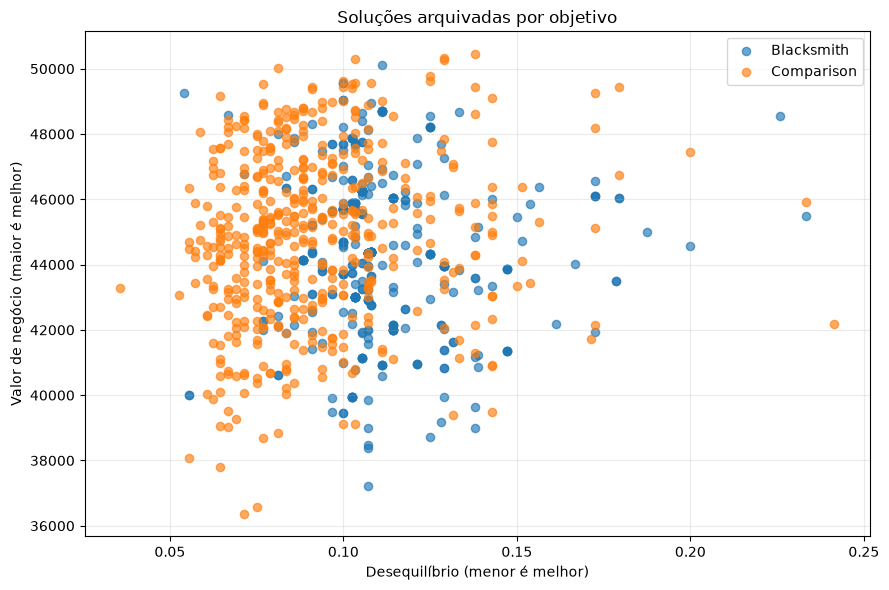

In [66]:
colors = {"blacksmith": "tab:blue", "comparison": "tab:orange"}
fig, ax = plt.subplots(figsize=(9, 6))

for algorithm, color in colors.items():
    points = [row for row in records if row["algorithm"] == algorithm]
    if points:
        ax.scatter(
            [row["imbalance"] for row in points],
            [row["business_value"] for row in points],
            label=algorithm.capitalize(),
            alpha=0.65,
            s=35,
            color=color,
        )

ax.set(title="Soluções arquivadas por objetivo", xlabel="Desequilíbrio (menor é melhor)", ylabel="Valor de negócio (maior é melhor)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Comparação pareada por execução

Cada ponto representa uma execução compartilhada pelos dois algoritmos. No eixo X, valores positivos indicam maior valor de negócio no Comparison; no eixo Y, valores positivos indicam menor desequilíbrio no Comparison. Cada métrica usa seu melhor valor no arquivo daquela execução; esses melhores podem vir de soluções diferentes.

In [ ]:
run_groups = {algorithm: {} for algorithm in colors}
for row in records:
    run_groups[row["algorithm"]].setdefault(row["run"], []).append(row)

paired_runs = sorted(
    set(run_groups["blacksmith"]) & set(run_groups["comparison"])
)
if not paired_runs:
    raise ValueError("No runs are shared by Blacksmith and Comparison")

comparisons = []
for run in paired_runs:
    blacksmith_run = run_groups["blacksmith"][run]
    comparison_run = run_groups["comparison"][run]
    comparisons.append(
        {
            "run": run,
            "business_value_delta": (
                max(row["business_value"] for row in comparison_run)
                - max(row["business_value"] for row in blacksmith_run)
            ),
            "imbalance_advantage": (
                min(row["imbalance"] for row in blacksmith_run)
                - min(row["imbalance"] for row in comparison_run)
            ),
        }
    )

categories = (
    ("Comparison melhor nos dois", "tab:green", lambda x, y: x > 0 and y > 0),
    ("Blacksmith melhor nos dois", "tab:blue", lambda x, y: x < 0 and y < 0),
    ("Trade-off ou empate", "tab:orange", lambda x, y: not (x > 0 and y > 0) and not (x < 0 and y < 0)),
)

fig, ax = plt.subplots(figsize=(9, 6))
for label, color, belongs in categories:
    points = [
        row for row in comparisons
        if belongs(row["business_value_delta"], row["imbalance_advantage"])
    ]
    if points:
        ax.scatter(
            [row["business_value_delta"] for row in points],
            [row["imbalance_advantage"] for row in points],
            label=label,
            color=color,
            alpha=0.75,
            s=45,
        )

ax.axhline(0, color="black", linewidth=1, alpha=0.7)
ax.axvline(0, color="black", linewidth=1, alpha=0.7)
ax.set(
    title=f"Diferença dos melhores objetivos por execução (n={len(paired_runs)})",
    xlabel="Diferença no melhor valor de negócio (Comparison - Blacksmith)",
    ylabel="Vantagem no menor desequilíbrio (Blacksmith - Comparison)",
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

## Solução inicial aleatória do Blacksmith

Os números identificam a execução dos pontos iniciais e finais; os pontos com o mesmo número pertencem à mesma execução.

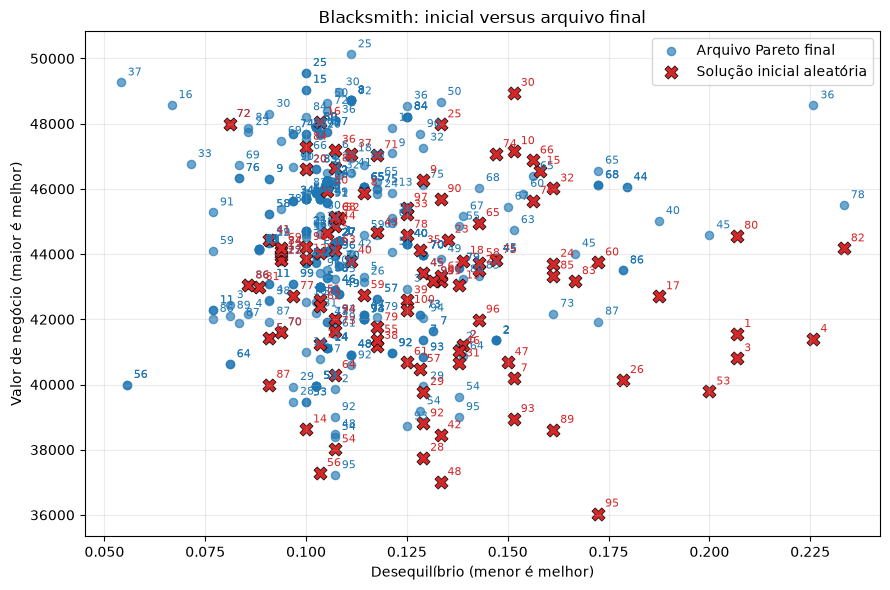

In [68]:
fig, ax = plt.subplots(figsize=(9, 6))

blacksmith_points = [row for row in records if row["algorithm"] == "blacksmith"]
if blacksmith_points:
    ax.scatter(
        [row["imbalance"] for row in blacksmith_points],
        [row["business_value"] for row in blacksmith_points],
        label="Arquivo Pareto final",
        alpha=0.65,
        s=35,
        color=colors["blacksmith"],
    )
    for point in blacksmith_points:
        ax.annotate(
            str(point["run"]),
            (point["imbalance"], point["business_value"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            color=colors["blacksmith"],
        )

if initial_solutions:
    ax.scatter(
        [row["imbalance"] for row in initial_solutions],
        [row["business_value"] for row in initial_solutions],
        label="Solução inicial aleatória",
        marker="X",
        s=90,
        color="tab:red",
        edgecolors="black",
        linewidths=0.5,
    )
    for initial in initial_solutions:
        ax.annotate(
            str(initial["run"]),
            (initial["imbalance"], initial["business_value"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            color="tab:red",
        )

ax.set(title="Blacksmith: inicial versus arquivo final", xlabel="Desequilíbrio (menor é melhor)", ylabel="Valor de negócio (maior é melhor)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Melhores objetivos por execução

Cada caixa resume a distribuição entre execuções. O máximo de valor e o mínimo de desequilíbrio podem pertencer a soluções diferentes; os painéis mostram as métricas separadamente.

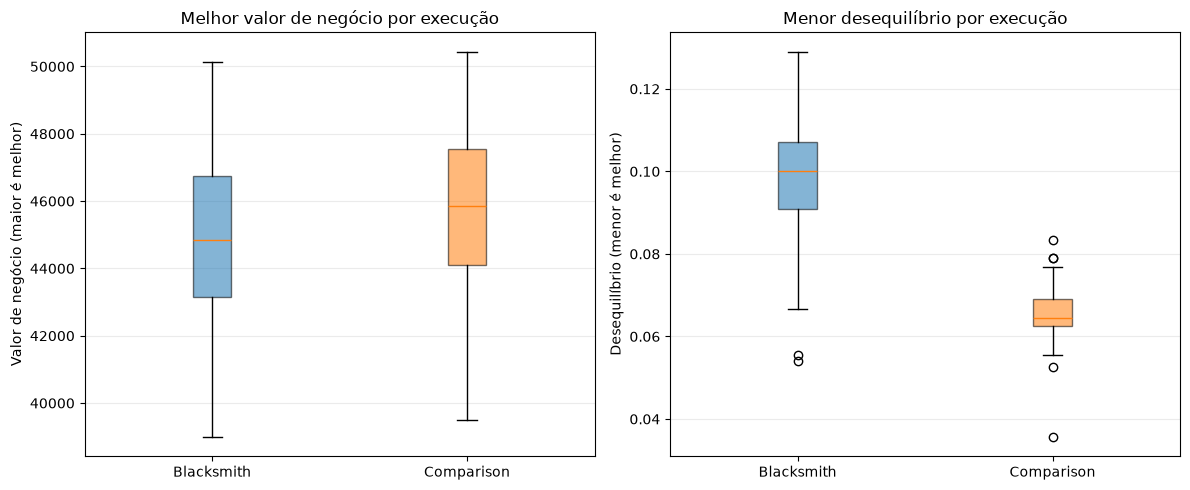

In [69]:
algorithms = [name for name in colors if any(row["algorithm"] == name for row in records)]
best_business_values = {
    algorithm: [
        max(row["business_value"] for row in records if row["algorithm"] == algorithm and row["run"] == run)
        for run in sorted({row["run"] for row in records if row["algorithm"] == algorithm})
    ]
    for algorithm in algorithms
}
lowest_imbalances = {
    algorithm: [
        min(row["imbalance"] for row in records if row["algorithm"] == algorithm and row["run"] == run)
        for run in sorted({row["run"] for row in records if row["algorithm"] == algorithm})
    ]
    for algorithm in algorithms
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title, ylabel in (
    (axes[0], best_business_values, "Melhor valor de negócio por execução", "Valor de negócio (maior é melhor)"),
    (axes[1], lowest_imbalances, "Menor desequilíbrio por execução", "Desequilíbrio (menor é melhor)"),
):
    box = ax.boxplot([data[name] for name in algorithms], tick_labels=[name.capitalize() for name in algorithms], patch_artist=True)
    for patch, name in zip(box["boxes"], algorithms):
        patch.set_facecolor(colors[name])
        patch.set_alpha(0.55)
    ax.set(title=title, ylabel=ylabel)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()